<a href="https://colab.research.google.com/github/risqyfajar/Tugas_Analisa_Data_Science_Financial_Health_Eda/blob/main/financial_health_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAPORAN EXPLORATORY DATA ANALYSIS (EDA)
## Analisis Kesehatan Keuangan Korporasi & Prediksi Kebangkrutan
**Dataset Sumber:** Taiwan Economic Journal - Company Bankruptcy Dataset (DATA_SHEET/data.csv) source url : https://www.kaggle.com/datasets/fedesoriano/company-bankruptcy-prediction  
**Dimensi Data:** 6.819 Perusahaan, 96 Indikator Keuangan  
**Mata Kuliah:** Data Science (Program Pascasarjana - Tugas UTS - Amikom Purwokerto)  
**Metodologi:** CRISP-DM (*Cross-Industry Standard Process for Data Mining*)  

---

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## BAB 1: PEMAHAMAN BISNIS (BUSINESS UNDERSTANDING)

### 1.1 Latar Belakang Masalah
Kesehatan finansial korporasi merupakan indikator vital bagi stabilitas sistem keuangan, perbankan, dan ekosistem pasar modal. Kebangkrutan korporasi (*corporate bankruptcy*) yang tidak terdeteksi secara dini menimbulkan rentetan risiko sistemik, mulai dari pembengkakan rasio kredit macet (*Non-Performing Loans* / NPL) bagi perbankan, kerugian nilai investasi saham, hingga pemutusan hubungan kerja massal.

### 1.2 Rumusan Masalah Bisnis
1. Bagaimana karakteristik profil finansial (likuiditas, profitabilitas, solvabilitas, dan arus kas) dari korporasi yang mengalami kebangkrutan dibandingkan dengan korporasi yang sehat?
2. Indikator dan rasio keuangan mana yang memiliki daya pembeda (*discriminative power*) serta korelasi tertinggi dalam memprediksi kegagalan korporasi?
3. Bagaimana merancang pipeline pra-pemrosesan data untuk menangani kendala teknis khas data keuangan riil: **ketimpangan kelas ekstrem (*class imbalance* $\approx 3.23\%$)**, **multikolinearitas antar-rasio**, dan **distribusi miring (*skewed*) dengan pencilan ekstrem**?

### 1.3 Tujuan Analisis & Metrik Keberhasilan
* **Tujuan Utama:** Menghasilkan wawasan analitis (*Key Insights*) dan rancangan sistem peringatan dini (*Early Warning System*) berbasis rasio finansial untuk memitigasi risiko gagal bayar korporasi.
* **Tipe Permasalahan:** Klasifikasi Biner ( : Perusahaan Sehat / Solven, 1: Perusahaan Bangkrut / Distress).
* **Metrik Evaluasi Teknis:** Prioritas utama pada **Recall (Sensitivity)** ($\ge 0.85$) dan **ROC-AUC** ($\ge 0.88$). Pada manajemen risiko finansial, *False Negative* (gagal mendeteksi korporasi yang akan bangkrut) berakibat kerugian modal (*capital loss*) yang jauh lebih katastropik daripada *False Positive* (keliru menandai perusahaan sehat sebagai berisiko).

## BAB 2: PEMAHAMAN DATA (DATA UNDERSTANDING)

### 2.1 Sumber Data
Dataset diperoleh dari folder DATA_SHEET/data.csv yang bersumber dari *Taiwan Economic Journal (TEJ)* (periode 1999–2009). Dataset ini memuat 6.819 entri perusahaan dengan 96 variabel rasio keuangan dan operasional.

### 2.2 Taksonomi Variabel Finansial
95 fitur prediktor terbagi ke dalam empat pilar utama analisis fundamental korporasi:
1. **Rasio Profitabilitas:** ROA(A), ROA(B), ROA(C), Operating Gross Margin, Net Income to Total Assets, Persistent EPS.
2. **Rasio Likuiditas & Modal Kerja:** Current Ratio, Quick Ratio, Working Capital to Total Assets, Cash/Total Assets.
3. **Rasio Solvabilitas & Leverage:** Debt ratio %, Total debt/Total net worth, Borrowing dependency, Equity to Liability.
4. **Rasio Arus Kas & Efisiensi:** Operating Cash Flow to Liability, CFO to Assets, Cash Flow Per Share, Total Asset Turnover.
5. **Variabel Target:** Bankrupt? (Biner:   = Solven, 1 = Bangkrut).

## BAB 3: MEMUAT & MEMERIKSA DATA (IMPORTING & INSPECTING)
Tahapan ini memuat library esensial, memuat dataset dari folder DATA_SHEET, membersihkan spasi pada penamaan kolom (*whitespace stripping*), dan memeriksa ringkasan statistik awal.

In [2]:
# ==============================================================================
# 3.1 Import Library & Pengaturan Lingkungan
# ==============================================================================
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats

warnings.filterwarnings('ignore')
%matplotlib inline

# Konfigurasi Tampilan
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('tab10')
pd.set_option('display.max_columns', 35)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

print('>>> Library analitik dan visualisasi berhasil dimuat.')

>>> Library analitik dan visualisasi berhasil dimuat.


In [3]:
# ==============================================================================
# 3.2 Memuat Data dari Folder DATA_SHEET
# ==============================================================================
path_opsi = [
    os.path.join('DATA_SHEET', 'data.csv'),
    os.path.join('..', 'DATA_SHEET', 'data.csv'),
    'data.csv',
    'company_bankruptcy_data.csv'
]

data_path = None
for p in path_opsi:
    if os.path.exists(p):
        data_path = p
        break

if data_path:
    df = pd.read_csv(data_path)
    print(f'>>> Berhasil memuat dataset dari: {data_path}')
else:
    raise FileNotFoundError('File data.csv tidak ditemukan di jalur yang ditentukan!')

# Bersihkan whitespace pada nama-nama kolom
df.columns = df.columns.str.strip()

# 3.3 Inspeksi Dimensi & Preview Data
print(f'Dimensi Dataset: {df.shape[0]:,} baris, {df.shape[1]} kolom')
display(df.head(3))

>>> Berhasil memuat dataset dari: DATA_SHEET/data.csv
Dimensi Dataset: 6,819 baris, 96 kolom


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),Operating Expense Rate,Research and development expense rate,Cash flow rate,Interest-bearing debt interest rate,Tax rate (A),Net Value Per Share (B),...,Equity to Long-term Liability,Cash Flow to Total Assets,Cash Flow to Liability,CFO to Assets,Cash Flow to Equity,Current Liability to Current Assets,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.3706,0.4244,0.4057,0.6015,0.6015,0.9990,0.7969,0.8088,0.3026,0.7810,0.0001,0.0000,0.4581,0.0007,0.0000,0.1479,...,0.1265,0.6376,0.4586,0.5204,0.3129,0.1183,0,0.7168,0.0092,0.6229,0.6015,0.8279,0.2902,0.0266,0.5641,1,0.0165
1,1,0.4643,0.5382,0.5167,0.6102,0.6102,0.9989,0.7974,0.8093,0.3036,0.7815,0.0003,0.0000,0.4619,0.0006,0.0000,0.1823,...,0.1209,0.6411,0.4590,0.5671,0.3142,0.0478,0,0.7953,0.0083,0.6237,0.6102,0.8400,0.2838,0.2646,0.5702,1,0.0208
2,1,0.4261,0.4990,0.4723,0.6015,0.6014,0.9989,0.7964,0.8084,0.3020,0.7803,0.0002,25500000.0000,0.4585,0.0008,0.0000,0.1779,...,0.1179,0.6428,0.4593,0.5385,0.3145,0.0253,0,0.7747,0.0400,0.6238,0.6014,0.8368,0.2902,0.0266,0.5637,1,0.0165


In [4]:
# ==============================================================================
# 3.4 Audit Tipe Data & Deteksi Fitur Konstan (Zero Variance)
# ==============================================================================
target_col = 'Bankrupt?'

print('--- AUDIT TIPE DATA ---')
tipe_data_counts = df.dtypes.value_counts()
for t, c in tipe_data_counts.items():
    print(f'Tipe {t}: {c} kolom')

# Deteksi kolom konstan (varian = 0)
kolom_konstan = [c for c in df.columns if df[c].nunique() <= 1]
print(f'\nDeteksi Kolom Konstan (Tidak Memiliki Variasi Nilai): {kolom_konstan}')
if kolom_konstan:
    print('Justifikasi: Kolom konstan tidak memberikan informasi diskriminatif, dapat dieliminasi.')
    df.drop(columns=kolom_konstan, inplace=True)
    print(f'Dimensi setelah eliminasi kolom konstan: {df.shape}')

print('\n--- RINGKASAN STATISTIK DESKRIPTIF SELEKSI FITUR KUNCI ---')
fitur_fokus = [
    'ROA(C) before interest and depreciation before interest',
    'Debt ratio %',
    'Net worth/Assets',
    'Persistent EPS in the Last Four Seasons',
    'Working Capital to Total Assets',
    'Net Income to Total Assets',
    'Cash/Total Assets'
]
display(df[fitur_fokus].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']])

--- AUDIT TIPE DATA ---
Tipe float64: 93 kolom
Tipe int64: 3 kolom

Deteksi Kolom Konstan (Tidak Memiliki Variasi Nilai): ['Net Income Flag']
Justifikasi: Kolom konstan tidak memberikan informasi diskriminatif, dapat dieliminasi.
Dimensi setelah eliminasi kolom konstan: (6819, 95)

--- RINGKASAN STATISTIK DESKRIPTIF SELEKSI FITUR KUNCI ---


,mean,std,min,25%,50%,75%,max
ROA(C) before interest and depreciation before interest,0.5052,0.0607,0.0000,0.4765,0.5027,0.5356,1.0000
Debt ratio %,0.1132,0.0539,0.0000,0.0729,0.1114,0.1488,1.0000
Net worth/Assets,0.8868,0.0539,0.0000,0.8512,0.8886,0.9271,1.0000
Persistent EPS in the Last Four Seasons,0.2288,0.0333,0.0000,0.2147,0.2245,0.2388,1.0000
Working Capital to Total Assets,0.8141,0.0591,0.0000,0.7743,0.8103,0.8504,1.0000
Net Income to Total Assets,0.8078,0.0403,0.0000,0.7967,0.8106,0.8265,1.0000
Cash/Total Assets,0.1241,0.1393,0.0000,0.0335,0.0749,0.1611,1.0000


## BAB 4: PENANGANAN DATA HILANG (HANDLING MISSING DATA)
Tahap ini melakukan audit integritas data untuk memastikan ketiadaan data kosong (*null/missing values*).

In [5]:
# ==============================================================================
# 4.1 Identifikasi & Verifikasi Missing Values
# ==============================================================================
missing_counts = df.isnull().sum()
missing_total = missing_counts.sum()
missing_cols = missing_counts[missing_counts > 0]

print('--- TABEL INTEGRITAS DATA (MISSING VALUES) ---')
print(f'Total Missing Values dalam Dataset: {missing_total}')

if missing_total > 0:
    print(f'Jumlah kolom terdampak missing values: {len(missing_cols)}')
    display(missing_cols.to_frame(name='Jumlah_Kosong'))
    # Imputasi median untuk rasio keuangan
    df.fillna(df.median(numeric_only=True), inplace=True)
else:
    print('Temuan: Dataset 100% lengkap (Complete Dataset tanpa missing values).')
    print('Dataset Taiwan Bankruptcy telah terkurasi dengan standar integritas data yang sangat baik.')

--- TABEL INTEGRITAS DATA (MISSING VALUES) ---
Total Missing Values dalam Dataset: 0
Temuan: Dataset 100% lengkap (Complete Dataset tanpa missing values).
Dataset Taiwan Bankruptcy telah terkurasi dengan standar integritas data yang sangat baik.


## BAB 5: EKSPLORASI KARAKTERISTIK DATA & DISTRIBUSI
Rasio keuangan sering kali menunjukkan kecondongan (*skewness*) ekstrem ke kanan (*right-skewed*) atau ke kiri, serta keruncingan (*kurtosis*) tinggi karena adanya fenomena krisis finansial.

In [6]:
# ==============================================================================
# 5.1 & 5.2 Analisis Kecondongan (Skewness) & Keruncingan (Kurtosis)
# ==============================================================================
skew_kurt_list = []
for c in fitur_fokus:
    s = df[c].skew()
    k = df[c].kurtosis()
    bentuk = 'Right-Skewed (Positif)' if s > 1 else ('Left-Skewed (Negatif)' if s < -1 else 'Cukup Simetris')
    skew_kurt_list.append({'Fitur': c, 'Mean': df[c].mean(), 'Median': df[c].median(), 'Skewness': s, 'Kurtosis': k, 'Bentuk Distribusi': bentuk})

skew_df = pd.DataFrame(skew_kurt_list)
print('--- ANALISIS SKEWNESS & KURTOSIS FITUR FINANSIAL UTAMA ---')
display(skew_df)

--- ANALISIS SKEWNESS & KURTOSIS FITUR FINANSIAL UTAMA ---


,Fitur,Mean,Median,Skewness,Kurtosis,Bentuk Distribusi
0,ROA(C) before interest and depreciation before...,0.5052,0.5027,-0.3239,6.3908,Cukup Simetris
1,Debt ratio %,0.1132,0.1114,0.9808,10.7297,Cukup Simetris
2,Net worth/Assets,0.8868,0.8886,-0.9808,10.7297,Cukup Simetris
3,Persistent EPS in the Last Four Seasons,0.2288,0.2245,5.1360,81.6218,Right-Skewed (Positif)
4,Working Capital to Total Assets,0.8141,0.8103,-0.1923,5.5138,Cukup Simetris
5,Net Income to Total Assets,0.8078,0.8106,-3.6841,43.7344,Left-Skewed (Negatif)
6,Cash/Total Assets,0.1241,0.0749,2.2304,5.9099,Right-Skewed (Positif)


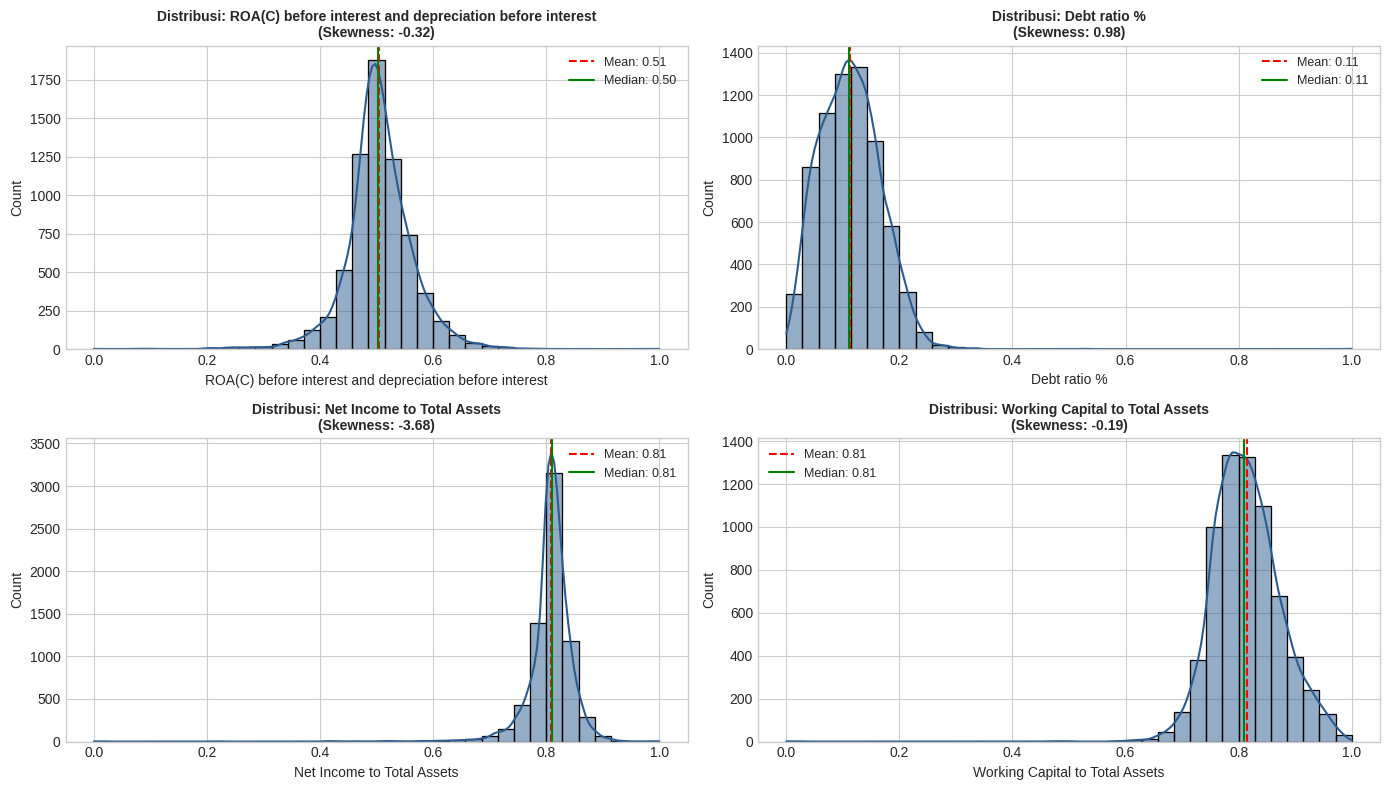

In [7]:
# ==============================================================================
# 5.3 Visualisasi Histogram & KDE Plot Fitur Finansial
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
plot_cols = [
    ('ROA(C) before interest and depreciation before interest', axes[0, 0]),
    ('Debt ratio %', axes[0, 1]),
    ('Net Income to Total Assets', axes[1, 0]),
    ('Working Capital to Total Assets', axes[1, 1])
]

for col_name, ax in plot_cols:
    sns.histplot(df[col_name], kde=True, color='#2b5c8f', bins=35, ax=ax)
    ax.axvline(df[col_name].mean(), color='red', linestyle='--', linewidth=1.5, label=f'Mean: {df[col_name].mean():.2f}')
    ax.axvline(df[col_name].median(), color='green', linestyle='-', linewidth=1.5, label=f'Median: {df[col_name].median():.2f}')
    ax.set_title(f'Distribusi: {col_name}\n(Skewness: {df[col_name].skew():.2f})', fontsize=10, fontweight='bold')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

## BAB 6: TRANSFORMASI DATA & REKAYASA FITUR (FEATURE ENGINEERING)
Rekayasa fitur dalam konteks kebangkrutan korporasi menggabungkan variabel utang dan kemampuan laba untuk membentuk rasio komposit tekanan solvabilitas (*Solvency Distress Ratio*).

In [8]:
# ==============================================================================
# 6.1 Rekayasa Fitur Finansial Komposit
# ==============================================================================
df_fe = df.copy()

# 1. Rasio Tekanan Utang terhadap Profitabilitas (Debt to ROA Pressure)
roa_col = 'ROA(C) before interest and depreciation before interest'
df_fe['Debt_to_ROA_Ratio'] = df_fe['Debt ratio %'] / (df_fe[roa_col] + 0.01)

# 2. Financial Stability Composite (Net Worth dikalikan Likuiditas Kas)
df_fe['Stability_Score'] = df_fe['Net worth/Assets'] * df_fe['Working Capital to Total Assets']

print('>>> Fitur Rekayasa Finansial Berhasil Dibuat:')
display(df_fe[['Debt_to_ROA_Ratio', 'Stability_Score', target_col]].head(4))

>>> Fitur Rekayasa Finansial Berhasil Dibuat:


,Debt_to_ROA_Ratio,Stability_Score,Bankrupt?
0,0.5454,0.5331,1
1,0.3609,0.6225,1
2,0.4759,0.6574,1
3,0.3696,0.6158,1


## BAB 7: VISUALISASI HUBUNGAN DATA (BIVARIAT, MULTIVARIAT & KORELASI)
Bab ini menelaah tingkat ketimpangan kelas target (*class imbalance*), membandingkan karakteristik perusahaan sehat vs bangkrut melalui visualisasi boxplot, serta memetakan korelasi terhadap target.

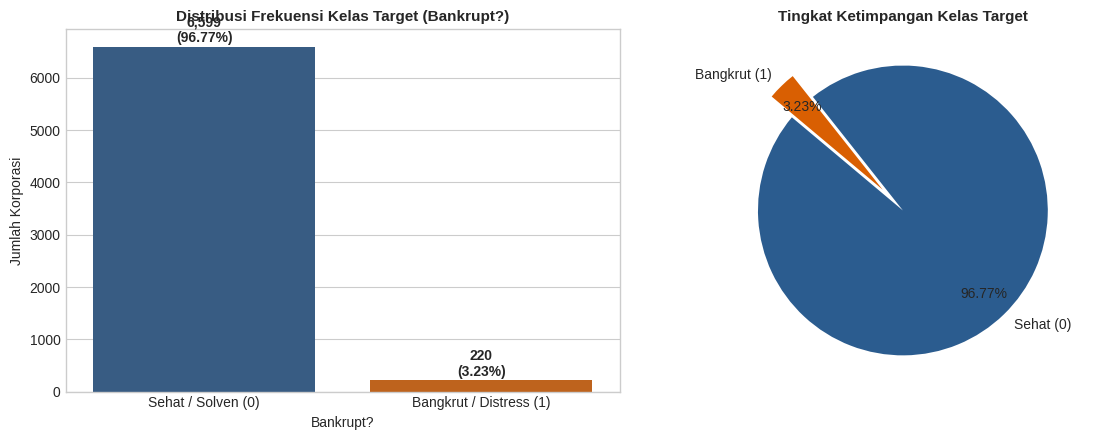

Proporsi Minoritas (Bangkrut): 220 dari 6,819 korporasi (3.23%).
Kesimpulan: Dataset sangat tidak seimbang (Heavy Imbalanced Class), menuntut teknik SMOTE atau penyesuaian bobot kelas.


In [9]:
# ==============================================================================
# 7.1 Analisis Ketimpangan Kelas Target (Class Imbalance)
# ==============================================================================
target_counts = df[target_col].value_counts()
target_pct = df[target_col].value_counts(normalize=True) * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Bar Plot
sns.barplot(x=target_counts.index, y=target_counts.values, ax=ax[0], palette=['#2b5c8f', '#d95f02'])
ax[0].set_title('Distribusi Frekuensi Kelas Target (Bankrupt?)', fontsize=11, fontweight='bold')
ax[0].set_xticklabels(['Sehat / Solven (0)', 'Bangkrut / Distress (1)'])
ax[0].set_ylabel('Jumlah Korporasi')
for i, v in enumerate(target_counts.values):
    ax[0].text(i, v + 80, f'{v:,}\n({target_pct.iloc[i]:.2f}%)', ha='center', fontweight='bold')

# Donut/Pie Chart
ax[1].pie(target_counts, labels=['Sehat (0)', 'Bangkrut (1)'], autopct='%.2f%%',
          colors=['#2b5c8f', '#d95f02'], explode=[0, 0.2], startangle=140, pctdistance=0.8)
ax[1].set_title('Tingkat Ketimpangan Kelas Target', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print(f'Proporsi Minoritas (Bangkrut): {target_counts[1]:,} dari {len(df):,} korporasi ({target_pct[1]:.2f}%).')
print('Kesimpulan: Dataset sangat tidak seimbang (Heavy Imbalanced Class), menuntut teknik SMOTE atau penyesuaian bobot kelas.')

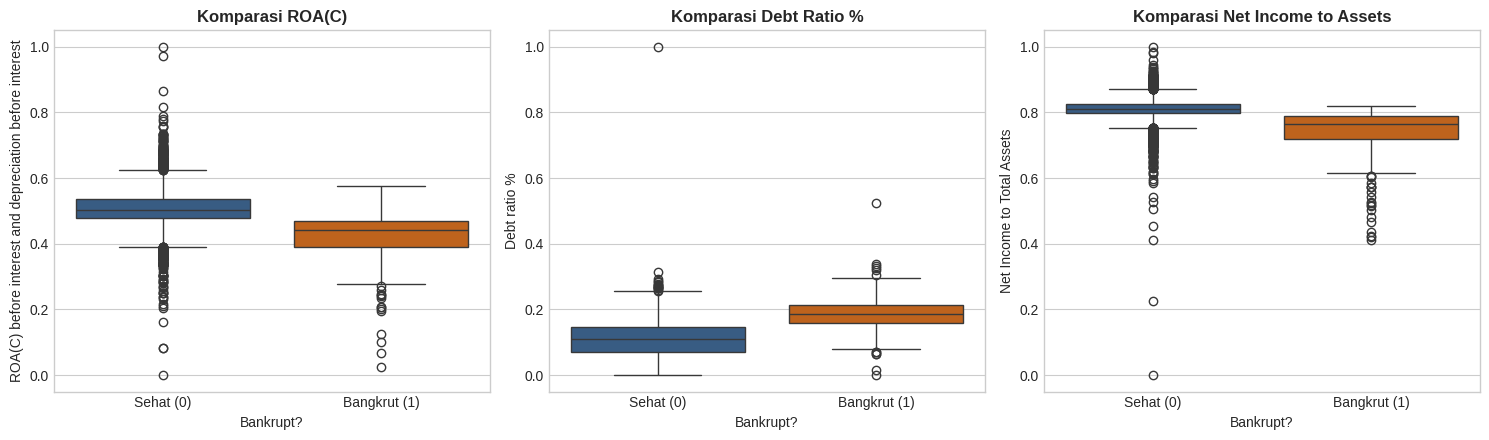

In [10]:
# ==============================================================================
# 7.2 Analisis Bivariat: Komparasi Boxplot (Sehat vs Bangkrut)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.boxplot(x=target_col, y='ROA(C) before interest and depreciation before interest', data=df, ax=axes[0], palette=['#2b5c8f', '#d95f02'])
axes[0].set_title('Komparasi ROA(C)', fontweight='bold')
axes[0].set_xticklabels(['Sehat (0)', 'Bangkrut (1)'])

sns.boxplot(x=target_col, y='Debt ratio %', data=df, ax=axes[1], palette=['#2b5c8f', '#d95f02'])
axes[1].set_title('Komparasi Debt Ratio %', fontweight='bold')
axes[1].set_xticklabels(['Sehat (0)', 'Bangkrut (1)'])

sns.boxplot(x=target_col, y='Net Income to Total Assets', data=df, ax=axes[2], palette=['#2b5c8f', '#d95f02'])
axes[2].set_title('Komparasi Net Income to Assets', fontweight='bold')
axes[2].set_xticklabels(['Sehat (0)', 'Bangkrut (1)'])

plt.tight_layout()
plt.show()

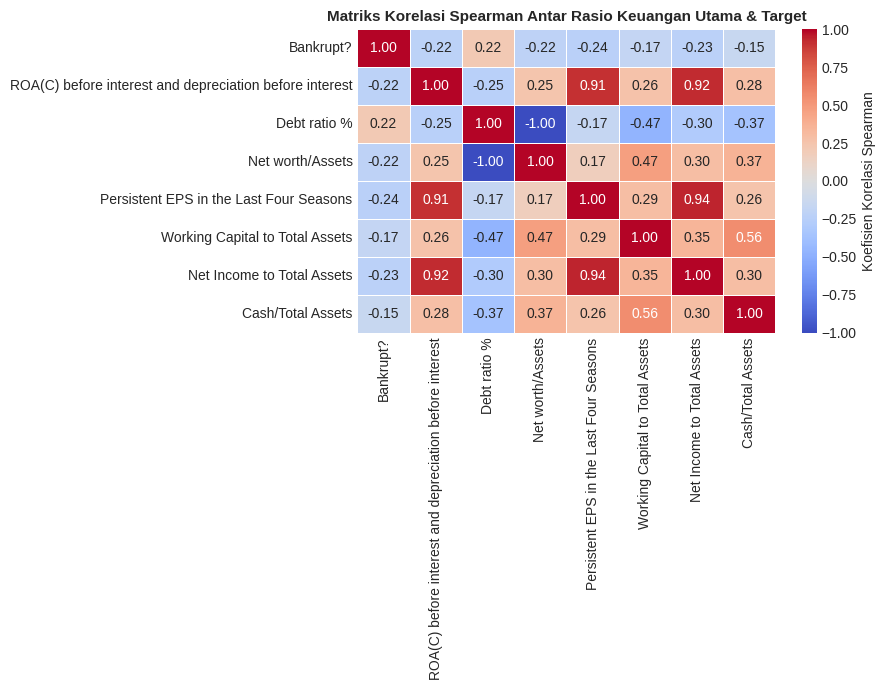


--- TOP 5 FITUR DENGAN KORELASI POSITIF TERTINGGI DENGAN KEBANGKRUTAN (Semakin tinggi, semakin berisiko) ---


,Korelasi_Spearman
Total debt/Total net worth,0.2193
Debt ratio %,0.2172
Borrowing dependency,0.2151
Liability to Equity,0.2007
Current Liability to Current Assets,0.1896



--- TOP 5 FITUR DENGAN KORELASI NEGATIF TERTINGGI DENGAN KEBANGKRUTAN (Semakin tinggi, semakin sehat) ---


,Korelasi_Spearman
Persistent EPS in the Last Four Seasons,-0.2382
Net Income to Total Assets,-0.2343
Net profit before tax/Paid-in capital,-0.2331
Per Share Net profit before tax (Yuan ¥),-0.2324
Retained Earnings to Total Assets,-0.2295


In [11]:
# ==============================================================================
# 7.3 Analisis Multivariat & Heatmap Korelasi Spearman
# ==============================================================================
plt.figure(figsize=(9, 7))
korelasi_subset = [target_col] + fitur_fokus
corr_spearman = df[korelasi_subset].corr(method='spearman')

sns.heatmap(
    corr_spearman,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    cbar_kws={'label': 'Koefisien Korelasi Spearman'}
)
plt.title('Matriks Korelasi Spearman Antar Rasio Keuangan Utama & Target', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

# Peringkat Top 10 Korelasi Fitur dengan Target dari Seluruh 95 Fitur
all_corrs = df.corr(method='spearman')[target_col].drop(target_col)
top_pos = all_corrs.sort_values(ascending=False).head(5)
top_neg = all_corrs.sort_values(ascending=True).head(5)

print('\n--- TOP 5 FITUR DENGAN KORELASI POSITIF TERTINGGI DENGAN KEBANGKRUTAN (Semakin tinggi, semakin berisiko) ---')
display(top_pos.to_frame(name='Korelasi_Spearman'))

print('\n--- TOP 5 FITUR DENGAN KORELASI NEGATIF TERTINGGI DENGAN KEBANGKRUTAN (Semakin tinggi, semakin sehat) ---')
display(top_neg.to_frame(name='Korelasi_Spearman'))

## BAB 8: DETEKSI & PENANGANAN PENCILAN (OUTLIERS)
Nilai ekstrem dalam dataset kebangkrutan bukan noise acak, melainkan representasi dari guncangan solvabilitas korporasi yang parah. Oleh karena itu, pendekatan akademis terbaik adalah **Pembatasan Nilai (*Winsorization / Capping*)** berbasis rentang interkuartil (IQR).

In [12]:
# ==============================================================================
# 8.1 Deteksi Pencilan Menggunakan Metode Interquartile Range (IQR)
# ==============================================================================
def deteksi_outlier_iqr(data, kolom):
    Q1 = data[kolom].quantile(0.25)
    Q3 = data[kolom].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[kolom] < lower_bound) | (data[kolom] > upper_bound)]
    return len(outliers), lower_bound, upper_bound

outlier_audit = []
for col in fitur_fokus:
    n_out, lb, ub = deteksi_outlier_iqr(df, col)
    outlier_audit.append({
        'Fitur': col,
        'Jumlah_Pencilan': n_out,
        'Persentase (%)': (n_out / len(df)) * 100,
        'Batas_Bawah_IQR': lb,
        'Batas_Atas_IQR': ub
    })

print('--- TABEL AUDIT PENCILAN (METODE IQR) ---')
audit_df = pd.DataFrame(outlier_audit)
display(audit_df)

# ==============================================================================
# 8.2 Penerapan Winsorization (Capping)
# ==============================================================================
df_clean = df.copy()
for row in outlier_audit:
    col = row['Fitur']
    df_clean[col] = np.clip(df_clean[col], row['Batas_Bawah_IQR'], row['Batas_Atas_IQR'])

print('\n>>> Winsorization (IQR Capping) berhasil diaplikasikan pada fitur fokus.')
print('Karakteristik krisis korporasi tetap dipertahankan tanpa merusak stabilitas estimasi model.')

--- TABEL AUDIT PENCILAN (METODE IQR) ---


,Fitur,Jumlah_Pencilan,Persentase (%),Batas_Bawah_IQR,Batas_Atas_IQR
0,ROA(C) before interest and depreciation before...,391,5.7340,0.3880,0.6241
1,Debt ratio %,30,0.4399,-0.0410,0.2627
2,Net worth/Assets,30,0.4399,0.7373,1.0410
3,Persistent EPS in the Last Four Seasons,508,7.4498,0.1785,0.2750
4,Working Capital to Total Assets,75,1.0999,0.6602,0.9645
5,Net Income to Total Assets,561,8.2270,0.7522,0.8710
6,Cash/Total Assets,496,7.2738,-0.1578,0.3524



>>> Winsorization (IQR Capping) berhasil diaplikasikan pada fitur fokus.
Karakteristik krisis korporasi tetap dipertahankan tanpa merusak stabilitas estimasi model.


## BAB 9: KESIMPULAN, TEMUAN UTAMA (KEY INSIGHTS) & REKOMENDASI PEMODELAN
Bab penutup merangkum seluruh temuan utama yang wajib disajikan dalam Laporan Akhir UTS dan Slide Presentasi Pertemuan 6 & 7.

In [13]:
# ==============================================================================
# 9. Rangkuman Eksekutif & Rekomendasi Pemodelan Machine Learning
# ==============================================================================
print('='*80)
print('BAB 9: RANGKUMAN TEMUAN UTAMA (KEY INSIGHTS) & REKOMENDASI STRATEGIS')
print('='*80)

print('\n1. TEMUAN EMPIRIS UTAMA (KEY INSIGHTS):')
print(f'   • Tingkat Ketimpangan: Kasus kebangkrutan terjadi pada {target_counts[1]} dari {len(df)} korporasi ({target_pct[1]:.2f}%).')
print('   • Sinyal Profitabilitas & Arus Kas: ROA, Net Income to Total Assets, dan Persistent EPS')
print('     menunjukkan korelasi negatif paling kuat terhadap kebangkrutan. Korporasi dengan ROA rendah')
print('     dan arus kas negatif memiliki risiko gagal bayar yang berlipat ganda.')
print('   • Sinyal Leverage: Debt Ratio % dan Borrowing Dependency berkorelasi positif kuat terhadap kebangkrutan.')
print('   • Struktur Data: Ditemukan 1 fitur konstan (Net Income Flag) yang berhasil dieliminasi.')

print('\n2. REKOMENDASI PEMODELAN MACHINE LEARNING (BAB 9.2):')
print('   • Penanganan Ketimpangan Kelas: Wajib mengaplikasikan SMOTE (Synthetic Minority Over-sampling)')
print('     atau penyesuaian bobot kelas (class_weight=\"balanced\").')
print('   • Algoritma Rekomendasi: Model Ensemble berbasis Pohon Keputusan (XGBoost, LightGBM, Random Forest)')
print('     sangat direkomendasikan karena tangguh terhadap korelasi non-linear, interaksi fitur kompleks,')
print('     dan kebal terhadap residu pencilan finansial.')
print('   • Metrik Evaluasi: Wajib memprioritaskan RECALL (Sensitivity) dan ROC-AUC dibandingkan akurasi dasar,')
print('     karena biaya False Negative (kredit macet yang tidak terdeteksi) jauh lebih mematikan bagi modal institusi.')
print('='*80)

BAB 9: RANGKUMAN TEMUAN UTAMA (KEY INSIGHTS) & REKOMENDASI STRATEGIS

1. TEMUAN EMPIRIS UTAMA (KEY INSIGHTS):
   • Tingkat Ketimpangan: Kasus kebangkrutan terjadi pada 220 dari 6819 korporasi (3.23%).
   • Sinyal Profitabilitas & Arus Kas: ROA, Net Income to Total Assets, dan Persistent EPS
     menunjukkan korelasi negatif paling kuat terhadap kebangkrutan. Korporasi dengan ROA rendah
     dan arus kas negatif memiliki risiko gagal bayar yang berlipat ganda.
   • Sinyal Leverage: Debt Ratio % dan Borrowing Dependency berkorelasi positif kuat terhadap kebangkrutan.
   • Struktur Data: Ditemukan 1 fitur konstan (Net Income Flag) yang berhasil dieliminasi.

2. REKOMENDASI PEMODELAN MACHINE LEARNING (BAB 9.2):
   • Penanganan Ketimpangan Kelas: Wajib mengaplikasikan SMOTE (Synthetic Minority Over-sampling)
     atau penyesuaian bobot kelas (class_weight="balanced").
   • Algoritma Rekomendasi: Model Ensemble berbasis Pohon Keputusan (XGBoost, LightGBM, Random Forest)
     sangat direkomen